**ИТОГОВАЯ АТТЕСТАЦИОННАЯ РАБОТА**  
по дополнительной профессиональной программе профессиональной переподготовки  
**Аналитик данных**  
Выполнил: Казанская Екатерина Дмитриевна  

  


**Тема: "Выделение портретов заемщиков банка"**

**Аналитическая задача** — провести анализ данных с целью выделения портретов заемщиков по каждой группе целевого признака.

**Примерный план исследования**

Шаг 1. Загрузка данных;

Шаг 2. Первичная обработка данных (при необходимости):
- скорректировать заголовки;
- скорректировать типы признаков;
- проверить наличие дублирующихся записей;
- проверить наличие аномальных значений;
- восстановить пропущенные значения;

Шаг 3. Добавление новых признаков:
- для каждого клиента рассчитайте его возраст на настоящий момент времени (на 2025 год);

Шаг 4. Исследовательский анализ данных
- в разрезе значений целевого признака (`Дисциплина клиентов без просрочки по кредиту`) исследовать распределения числовых и категориальных признаков;
- в разрезе значений целевого признака составить портреты клиентов платежной системы.

# Подключение библиотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
from scipy import stats

# Блок пользовательских функций

In [43]:
def calc_boxplot(df_col : pd.Series) -> tuple:

    """
    Функция для расчета значений нижнего и верхнего усов.
    На вход подается столбец датафрейма,
    на выходе кортеж: первый элемент -- нижний ус, второй элемент -- верхний ус
    """

    Q1, median, Q3 = np.percentile(np.asarray(df_col.dropna()), [25, 50, 75])
    IQR = Q3 - Q1
    loval = Q1 - 1.5 * IQR
    hival = Q3 + 1.5 * IQR
    wiskhi = np.compress(np.asarray(df_col.dropna()) <= hival, np.asarray(df_col.dropna()))
    wisklo = np.compress(np.asarray(df_col.dropna()) >= loval, np.asarray(df_col.dropna()))
    actual_hival = np.max(wiskhi)
    actual_loval = np.min(wisklo)
    return actual_loval, actual_hival #(нижний ус, верхний ус)

# Шаг 1. Загрузка и ознакомление с данными

In [44]:
# Загрузка данных
df = pd.read_csv('/content/dataset_segment_bank.csv')
df.head(10)

,Идентификатор,Дата рождения,Дисциплина клиентов без просрочки по кредиту,Количество переводов,Тип переводов,География переводов,География телефона,Сумма перевода,Максимальная сумма перевода,Средняя сумма перевода,Полная сумма перевода,"Канал, через который пришел клиент",Оператор связи,Пол
0,1493553,1981-05-08,BAD,17.0,2.0,77.0,77.0,371600.00,265000.0,21858.8235,371600.00,Стойка,NaN,Ж
1,8130758,1979-03-06,BAD,4.0,2.0,77.0,77.0,137574.00,135000.0,34393.5000,137574.00,Стойка,NaN,М
2,1782539,1957-04-29,BAD,3.0,2.0,77.0,77.0,175150.00,135000.0,58383.3333,175150.00,Стойка,МегаФон,М
3,12410720,1977-08-05,BAD,3.0,2.0,77.0,77.0,50250.00,50000.0,16750.0000,50250.00,Стойка,NaN,М
4,21309736,1978-08-15,GOOD,5.0,69.0,77.0,77.0,215920.14,135000.0,43184.0280,215920.14,Стойка,NaN,М
5,11343857,1983-05-06,BAD,2.0,1.0,77.0,77.0,50150.00,50000.0,25075.0000,50150.00,Стойка,NaN,Ж
6,5383517,1972-02-01,BAD,4.0,2.0,77.0,77.0,204150.00,200000.0,51037.5000,204150.00,Стойка,NaN,Ж
7,3882794,1979-05-20,BAD,15.0,5.0,77.0,77.0,538300.00,400000.0,35886.6666,538300.00,Стойка,NaN,Ж
8,7119607,1969-08-18,BAD,4.0,2.0,77.0,77.0,135335.00,135000.0,33833.7500,135335.00,Офис,NaN,Ж
9,7369177,1964-12-17,BAD,9.0,2.0,77.0,77.0,62310.00,38000.0,6923.3333,62310.00,Офис,Вымпел-Коммуникации,Ж


In [45]:
# просмотр информации о типах данных
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50224 entries, 0 to 50223
Data columns (total 14 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Идентификатор                                 50224 non-null  int64  
 1   Дата рождения                                 50224 non-null  object 
 2   Дисциплина клиентов без просрочки по кредиту  50223 non-null  object 
 3   Количество переводов                          50158 non-null  float64
 4   Тип переводов                                 50191 non-null  float64
 5   География переводов                           50191 non-null  float64
 6   География телефона                            48324 non-null  float64
 7   Сумма перевода                                50158 non-null  float64
 8   Максимальная сумма перевода                   50158 non-null  float64
 9   Средняя сумма перевода                        50158 non-null 

In [46]:
# просмотр описательных статистик
perc = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
df.describe(percentiles=perc)

,Идентификатор,Количество переводов,Тип переводов,География переводов,География телефона,Сумма перевода,Максимальная сумма перевода,Средняя сумма перевода,Полная сумма перевода
count,5.022400e+04,50158.000000,50191.000000,50191.000000,48324.000000,5.015800e+04,5.015800e+04,50158.000000,5.015800e+04
mean,1.097869e+07,17.290821,13.186328,110.217888,58.161183,2.995784e+05,1.676934e+05,34478.895504,2.995784e+05
std,5.760869e+06,34.801316,22.298265,4969.776700,22.708184,4.527366e+05,1.410307e+05,43548.644155,4.527366e+05
min,1.400402e+06,1.000000,-1.000000,0.000000,0.000000,3.000000e+01,3.000000e+01,30.000000,3.000000e+01
1%,1.552898e+06,1.000000,0.000000,2.000000,2.000000,2.380555e+04,1.041879e+04,2318.792510,2.380555e+04
5%,2.228634e+06,2.000000,2.000000,13.000000,10.000000,4.000000e+04,3.000000e+04,4381.164050,4.000000e+04
25%,6.397864e+06,4.000000,2.000000,48.000000,40.000000,9.225300e+04,5.500000e+04,10108.333300,9.225300e+04
50%,1.133596e+07,9.000000,5.000000,73.000000,66.000000,1.877303e+05,1.200000e+05,19831.931800,1.877303e+05
75%,1.444163e+07,18.000000,6.000000,77.000000,77.000000,3.831000e+05,2.350000e+05,41650.750000,3.831000e+05
95%,2.209581e+07,58.000000,69.000000,78.000000,78.000000,8.242231e+05,4.900000e+05,113383.333300,8.242231e+05


In [47]:
# сравним значения в признаках  'Сумма перевода' и 'Полная сумма перевода'
df.loc[~(df['Сумма перевода'] == df['Полная сумма перевода'])].info()
# во всех строках, кроме 66(из 41497) значения совпадают, можем удалить один из этих столбцов

<class 'pandas.core.frame.DataFrame'>
Index: 66 entries, 50158 to 50223
Data columns (total 14 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Идентификатор                                 66 non-null     int64  
 1   Дата рождения                                 66 non-null     object 
 2   Дисциплина клиентов без просрочки по кредиту  66 non-null     object 
 3   Количество переводов                          0 non-null      float64
 4   Тип переводов                                 33 non-null     float64
 5   География переводов                           33 non-null     float64
 6   География телефона                            28 non-null     float64
 7   Сумма перевода                                0 non-null      float64
 8   Максимальная сумма перевода                   0 non-null      float64
 9   Средняя сумма перевода                        0 non-null      flo

In [48]:
# посмотрим уникальные значения в признаках с типом 'object'
for col in df.select_dtypes('object').columns:
    print(f'Уникальные значения признака <<<{col}>>>')
    print(df[col].unique())
    print('-'*10)
    print()

Уникальные значения признака <<<Дата рождения>>>
['1981-05-08' '1979-03-06' '1957-04-29' ... '1965-11-12' '1990-06-12'
 '1975-04-01']
----------

Уникальные значения признака <<<Дисциплина клиентов без просрочки по кредиту>>>
['BAD' 'GOOD' 'MIDDLE' nan]
----------

Уникальные значения признака <<<Канал, через который пришел клиент>>>
['Стойка' 'Офис' 'Партнер' nan]
----------

Уникальные значения признака <<<Оператор связи>>>
[nan 'МегаФон' 'Вымпел-Коммуникации' 'Мобильные ТелеСистемы'
 'Вотек Мобайл' 'Нижегородская сотовая связь' 'МобильныеТелеСистемы'
 'Санкт-Петербург Телеком' 'Телеком Евразия' 'Кемеровская Мобильная Связь'
 'Средневолжская межрегиональная ассоциация радиотел'
 'Ростовская Сотовая Связь' 'Ростелеком' 'Смоленская Сотовая Связь'
 'Челябинская Сотовая Связь' 'ЕКАТЕРИНБУРГ-2000' 'Телесет Лтд.'
 'Сотовая Связь Удмуртии' 'Персональные Системы Связи в Регионе'
 'Белгородская Сотовая Связь' 'Сибирская Сотовая Связь' 'Волгоград-GSM'
 'Ниж-ская сот.связь' 'Енисейтелеком' 'Нов

## Выводы

Данные загружены корректно;  
обнаружены следующие особенности данных:

|Признак|Комментарий|
|--:|:--|
|`all`|сделать лаконичные заголовки|
|`География телефона`,`Канал, через который пришел клиент`,|в признаках есть пропуски|
|`Оператор связи`,`Пол` |в признаках есть пропуски|
|`Сумма перевода`,`Полная сумма перевода`|значения в признаках совпадают, можно удалить дублир. признак|
|`Средняя сумма перевода`|производное от признаков `Количество переводов` и `Полная сумма перевода`|
|`Дата рождения`|поменять тип данных на дату|
|`Тип переводов`|есть отрицательное значение, проверить|
||имеются текстовые признаки.Проверить уник значения|
|Количество переводов|Подозрение на аномалию|
|||


# Шаг 2. Первичная обработка данных (при необходимости)

## Удаление дублирующихся столбцов

In [49]:
# предобработка: удаление дублирующихся столбцов (если имеются)
lst_var_drop = ['Средняя сумма перевода',
                'Полная сумма перевода']
df.drop(columns = lst_var_drop,
        inplace=True)

## Корректировка заголовков

In [50]:
# предобработка: переименование столбцов
# приведение к нижнему регистру
df.columns = df.columns.str.lower()

df.rename(columns={'дисциплина клиентов без просрочки по кредиту': 'дисциплина клиента',
                   'канал, через который пришел клиент': 'канал клиента',
                   'максимальная сумма перевода': 'макс сумма перевода'
                   },
          inplace=True)
# замена пробелов на символ _
df.columns = ['_'.join(col.split()) for col in df.columns]

## Предобработка данных: корректировка типов

In [51]:
# предобработка: скорректировать типы признаков;
df = df.astype({'дата_рождения': 'datetime64[s]'},
           errors = 'ignore')

## Предобработка данных: поиск дублей

In [52]:
# проверить наличие дублирующихся записей;
df.duplicated().sum()
# видим, что есть 575 дублирующихся строк

np.int64(575)

In [53]:
# просмотр дублирующихся записей
df.loc[df.duplicated()]

,идентификатор,дата_рождения,дисциплина_клиента,количество_переводов,тип_переводов,география_переводов,география_телефона,сумма_перевода,макс_сумма_перевода,канал_клиента,оператор_связи,пол
285,13429088,1984-09-12,MIDDLE,89.0,2.0,77.0,33.0,573174.03,25950.0,Партнер,Вотек Мобайл,М
334,13429088,1984-09-12,MIDDLE,89.0,2.0,77.0,33.0,573174.03,25950.0,Партнер,Вотек Мобайл,М
459,17591794,1974-09-28,MIDDLE,22.0,5.0,77.0,NaN,78746.00,10200.0,Партнер,Мобильные ТелеСистемы,М
466,17591794,1974-09-28,MIDDLE,22.0,5.0,77.0,NaN,78746.00,10200.0,Партнер,Мобильные ТелеСистемы,М
528,4872767,1968-02-18,BAD,13.0,2.0,77.0,77.0,316064.16,150000.0,Стойка,NaN,М
...,...,...,...,...,...,...,...,...,...,...,...,...
50149,8551974,1979-12-02,GOOD,471.0,16.0,77.0,23.0,2029892.53,30000.0,Партнер,Вымпел-Коммуникации,М
50150,8551974,1979-12-02,GOOD,471.0,16.0,77.0,23.0,2029892.53,30000.0,Партнер,Вымпел-Коммуникации,М
50151,8551974,1979-12-02,GOOD,471.0,16.0,77.0,23.0,2029892.53,30000.0,Партнер,Вымпел-Коммуникации,М
50152,8551974,1979-12-02,GOOD,471.0,16.0,77.0,23.0,2029892.53,30000.0,Партнер,Вымпел-Коммуникации,М


In [54]:
# поиск дублей без одного признака - 'идентификатор' если идентификаторы разные
df.drop(columns='идентификатор').duplicated().sum()

np.int64(575)

In [55]:
# удаление дублирующихся записей
df.drop_duplicates(inplace=True)

In [56]:
# проверка что дубли удалены
df.duplicated().sum()

np.int64(0)

In [57]:
df.shape


(49649, 12)

## Предобработка: поиск и обработка аномальных значений

In [58]:
# список непрерывных признаков
lst_var_cont = [
    'количество_переводов',
    'сумма_перевода',
    'макс_сумма_перевода'
]

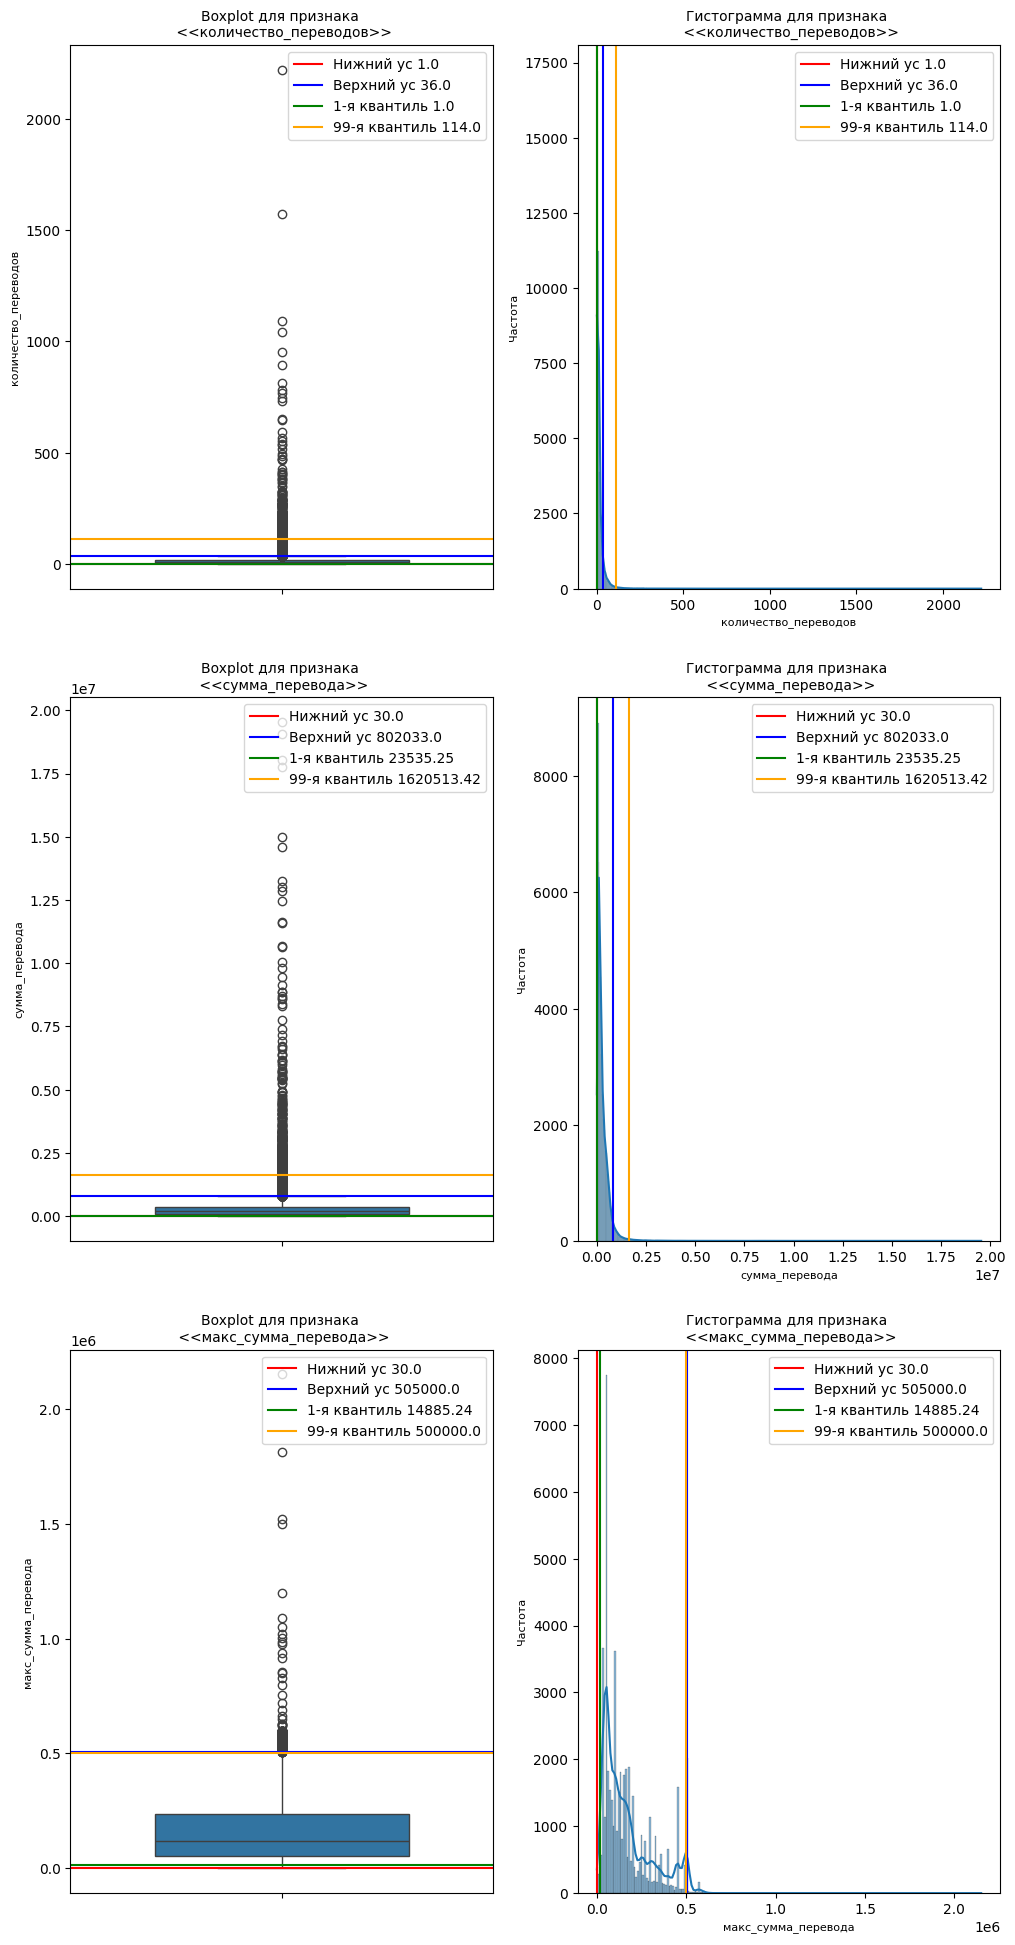

In [59]:
fig, ax = plt.subplots(3, 2, figsize = (12, 24))

for index, col in enumerate(lst_var_cont): #перебираем в цикле заголовки признаков `col` и сразу же генерируем номер рисунка `index`
    plt.subplot(3, 2, 2*index + 1) #задаем рисунок с нужным нечетным номером (нумерация начинается с 1)
    ax = sns.boxplot(y = df[col], width=0.6) #рисуем ящик
    plt.title(f'Boxplot для признака \n <<{col}>>', fontsize = 10) #заголовок рисунка
    plt.ylabel(f'{col}', fontsize = 8) #подпись оси ординат
    plt.xlabel('', fontsize = 8) #подпись оси абцисс
    value_low, value_upper = calc_boxplot(df[col])
        #считаем 1 и 99 квантили
    per_1 = np.percentile(df[col].dropna(), 1)
    per_99 = np.percentile(df[col].dropna(), 99)
    plt.axhline(value_low, #значение координаты по оси ординат -- горизонтальная линия имеет координаты (0, value_low)
                color = 'red', # цвет линии
                label = 'Нижний ус {}'.format(np.round(value_low,2)) #текст для легенды -- отображаем значение уса, округленное до 2 знаков
                )
    plt.axhline(value_upper, #значение координаты по оси ординат -- горизонтальная линия имеет координаты (0, value_upper)
                color = 'blue', # цвет линии
                label = 'Верхний ус {}'.format(np.round(value_upper,2)) #текст для легенды -- отображаем значение уса, округленное до 2 знаков
                )

    plt.axhline(per_1, #значение координаты по оси ординат -- вертикальная линия имеет координаты (0, per_1)
                color = 'green', # цвет линии
                label = '1-я квантиль {}'.format(np.round(per_1,2)) #текст для легенды -- отображаем значение квантиля, округленное до 2 знаков
                )
    plt.axhline(per_99, #значение координаты по оси абцисс -- вертикальная линия имеет координаты (0, per_99)
                color = 'orange', # цвет линии
                label = '99-я квантиль {}'.format(np.round(per_99,2)) #текст для легенды -- отображаем значение квантиля, округленное до 2 знаков
                )

    plt.legend(loc='upper right') #отображаем легенду, принудительно размещая ее в правом верхнем углу

    #четные рисунки -- рисуем гистограммы и плотности
    plt.subplot(3, 2, 2*index + 2)
    ax = sns.histplot(df[col], #признак
                      kde = True #для рисования функции плотности
                      )


    #вначале рисуем усы на плотности в виде вертикальных линий -- метод axvline()

    plt.axvline(value_low, #значение координаты по оси ординат -- горизонтальная линия имеет координаты (0, value_low)
                color = 'red', # цвет линии
                label = 'Нижний ус {}'.format(np.round(value_low,2)) #текст для легенды -- отображаем значение уса, округленное до 2 знаков
                )
    plt.axvline(value_upper, #значение координаты по оси ординат -- горизонтальная линия имеет координаты (0, value_upper)
                color = 'blue', # цвет линии
                label = 'Верхний ус {}'.format(np.round(value_upper,2)) #текст для легенды -- отображаем значение уса, округленное до 2 знаков
                )

    plt.legend(loc='upper right') #отображаем легенду, принудительно размещая ее в правом верхнем углу

    #рисуем квантили

    plt.axvline(per_1, #значение координаты по оси ординат -- вертикальная линия имеет координаты (0, per_1)
                color = 'green', # цвет линии
                label = '1-я квантиль {}'.format(np.round(per_1,2)) #текст для легенды -- отображаем значение квантиля, округленное до 2 знаков
                )
    plt.axvline(per_99, #значение координаты по оси абцисс -- вертикальная линия имеет координаты (0, per_99)
                color = 'orange', # цвет линии
                label = '99-я квантиль {}'.format(np.round(per_99,2)) #текст для легенды -- отображаем значение квантиля, округленное до 2 знаков
                )

    plt.legend(loc='upper right') #отображаем легенду, принудительно размещая ее в правом верхнем углу
    plt.title(f'Гистограмма для признака \n <<{col}>>', fontsize = 10) #заголовок рисунка
    plt.ylabel('Частота', fontsize = 8) #подпись оси ординат
    plt.xlabel(f'{col}', fontsize = 8) #подпись оси абцисс

In [60]:
# Сохраняем все наблюдения, поскольку экстремальные значения
# не обязательно являются ошибочными
df_not_anomals = df.copy()

print(f'Количество строк после проверки: {df_not_anomals.shape[0]}')

Количество строк после проверки: 49649


In [61]:
# Проверяем пропуски в признаках, по которым искали выбросы
df[lst_var_cont].isna().sum()

,0
количество_переводов,66
сумма_перевода,66
макс_сумма_перевода,66


In [62]:
# df_not_anomals.info()
# просмотр описательных статистик после первичной предобработки данных
perc = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
df_not_anomals.describe(percentiles=perc)

,идентификатор,дата_рождения,количество_переводов,тип_переводов,география_переводов,география_телефона,сумма_перевода,макс_сумма_перевода
count,4.964900e+04,49649,49583.000000,49616.000000,49616.000000,47781.000000,4.958300e+04,4.958300e+04
mean,1.097182e+07,1970-08-30 08:16:53,15.886130,13.224484,110.669744,58.206735,2.943397e+05,1.680532e+05
min,1.400402e+06,1940-01-20 00:00:00,1.000000,-1.000000,0.000000,0.000000,3.000000e+01,3.000000e+01
1%,1.552769e+06,1947-04-12 00:00:00,1.000000,0.000000,2.000000,2.000000,2.353525e+04,1.488524e+04
5%,2.226812e+06,1952-02-01 19:12:00,2.000000,2.000000,13.000000,10.000000,3.993920e+04,3.000000e+04
25%,6.377852e+06,1962-04-28 00:00:00,4.000000,2.000000,48.000000,42.000000,9.137250e+04,5.500000e+04
50%,1.134104e+07,1971-04-29 00:00:00,9.000000,5.000000,73.000000,66.000000,1.857500e+05,1.200000e+05
75%,1.444320e+07,1979-06-28 00:00:00,17.000000,6.000000,77.000000,77.000000,3.759768e+05,2.350000e+05
95%,2.210644e+07,1987-03-16 00:00:00,53.000000,69.000000,78.000000,78.000000,8.032824e+05,4.900000e+05
99%,2.598152e+07,1989-07-19 12:28:47,114.000000,69.000000,78.000000,78.000000,1.620513e+06,5.000000e+05


## Предобработка: обработка категориальных признаков

In [63]:
# список категориальных признаков
lst_cat_vars = ['тип_переводов', 'география_переводов',
       'география_телефона','канал_клиента',
        'оператор_связи', 'пол']

In [64]:
# посмотрим часто встречающиеся значения
for col in lst_cat_vars:
    print(f'------- Признак: {col} --------')
    print(df[col].value_counts())
    print('---------------')
    print('---------------')

------- Признак: тип_переводов --------
тип_переводов
 2.0     18673
 5.0     13778
 69.0     6527
 6.0      2542
 8.0      1991
 1.0      1633
 10.0     1549
 0.0       739
 12.0      468
 26.0      289
 32.0      253
 16.0      248
 37.0      220
 11.0      194
 45.0      157
 7.0       139
 44.0       62
 58.0       45
 3.0        30
 28.0       14
 21.0       14
 33.0        7
 29.0        6
 4.0         5
 23.0        5
 19.0        5
 55.0        3
 54.0        3
 17.0        3
 53.0        2
 59.0        2
 61.0        2
 34.0        2
 43.0        1
 67.0        1
 30.0        1
-1.0         1
 9.0         1
 49.0        1
Name: count, dtype: int64
---------------
---------------
------- Признак: география_переводов --------
география_переводов
77.0        19144
78.0         4140
61.0         2338
23.0         2113
66.0         1502
            ...  
75.0            2
498001.0        2
6.0             1
20.0            1
19.0            1
Name: count, Length: 74, dtype: int64
-

In [65]:
# замена низкочастотных значений признака 'тип_переводов' на одно
limit_value = 100
filt1 = df_not_anomals['тип_переводов'].value_counts() <  limit_value
value_replace = list(df_not_anomals['тип_переводов'].value_counts().loc[filt1].index)
dct_value_replace = dict.fromkeys(value_replace, 'другие_типы_переводов')
df_not_anomals['тип_переводов'] = df_not_anomals['тип_переводов'].replace(dct_value_replace)

In [66]:
# обработаем значения в признаке 'география_переводов',
# всем переводам, количество которых меньше 1000 присвоим значение 1000.00
df_not_anomals['география_переводов'] = df_not_anomals['география_переводов'].replace(
                            {k: '1000.0'
                            for k, v in df_not_anomals['география_переводов'].value_counts().items() if v < 1000}
)

In [67]:
# обработаем значения в признаке 'география_телефона',
# всем переводам, количество которых меньше 1000 присвоим значение 1000.0
df_not_anomals['география_телефона'] = df_not_anomals['география_телефона'].replace(
                            {k: '1000.0'
                            for k, v in df_not_anomals['география_телефона'].value_counts().items() if v < 1000}
)

In [68]:
# обработаем значения в признаке 'оператор_связи'
# поскольку наибольшее кол-во клиентов распределено по трем основным операторам,
# остальных операторов объединим в одну группу - прочие
values_to_replace = {'Мобильные ТелеСистемы' : 'МТС',
                     'МобильныеТелеСистемы' : 'МТС'}
df_not_anomals.replace(values_to_replace,
           inplace=True)

df_not_anomals['оператор_связи'] = df_not_anomals['оператор_связи'].replace(
                            {k: 'прочие_операторы'
                            for k, v in df_not_anomals['оператор_связи'].value_counts().items() if v < 10000}
)

## Предобработка: работа с пропущенными значениями

In [69]:
# Оценка пропущенных значений
missing_percent = df_not_anomals.isna().sum().sum() / df_not_anomals.size * 100

print(f'Доля пропущенных значений: {missing_percent:.2f}%')

df_not_anomals.isna().sum()

Доля пропущенных значений: 0.47%


,0
идентификатор,0
дата_рождения,0
дисциплина_клиента,1
количество_переводов,66
тип_переводов,33
география_переводов,33
география_телефона,1868
сумма_перевода,66
макс_сумма_перевода,66
канал_клиента,31


In [ ]:
# проанализированы пропущенные значения: их доля составляет 0,47% от общего количества ячеек.
# Пропуски сохранены для дальнейшей обработки с учётом задач анализа.

## Выводы

Проведены следующие работы:
- были удалены дублирующиеся столбцы;
- скорректированы заголовки признаков;  
- скорректированы типы данных соответствующих столбцов;  
- удалены дублирующиеся записи;  
- проанализированы распределения непрерывных признаков с помощью boxplot и перцентилей;
- выявлены экстремальные значения, которые сохранены в наборе данных, поскольку они не обязательно являются ошибочными;
- проанализированы пропущенные значения: их доля составляет 0,47% от общего количества ячеек. Пропуски сохранены для дальнейшей обработки с учётом задач анализа.




# Шаг 3. Добавление новых признаков:

In [70]:
# Выделим числовые и категориальные признаки

lst_var_num = [
    'количество_переводов',
    'сумма_перевода',
    'макс_сумма_перевода',
    'возраст_клиента'
]

lst_var_disc = [
    'дисциплина_клиента',
    'тип_переводов',
    'география_переводов',
    'география_телефона',
    'канал_клиента',
    'оператор_связи',
    'пол'
]

In [71]:
# для каждого клиента рассчитаем его возраст на настоящий момент времени (на 2026 год);

In [72]:
# приводим столбец к datetime
df_not_anomals['дата_рождения'] = pd.to_datetime(df_not_anomals['дата_рождения'])

# текущая дата
today = pd.Timestamp('today').normalize()

# точный возраст
df_not_anomals['возраст_клиента'] = today.year - df_not_anomals['дата_рождения'].dt.year - (
    (today.month < df_not_anomals['дата_рождения'].dt.month) |
    ((today.month == df_not_anomals['дата_рождения'].dt.month) & (today.day < df_not_anomals['дата_рождения'].dt.day))
)

## Выводы

На этом этапе был добавлен новый признак `возраст_клиента`

# Шаг 4. Исследовательский анализ данных

In [ ]:
# в разрезе значений целевого признака (Дисциплина клиентов без просрочки по кредиту)
# исследовать распределения числовых и категориальных признаков;
# в разрезе значений целевого признака составить портреты клиентов платежной системы.

## Исследование распределения числовых признаков в разрезе значений целевого признака `Дисциплина клиентов без просрочки по кредиту`

In [73]:
# рассчитаем оценки параметров среднего положения для непрерыв признаков в разрезе Дисциплины
df_not_anomals.groupby('дисциплина_клиента')[lst_var_num].agg(['mean', 'median'])

количество_переводов        сумма_перевода            \
                                   mean median           mean    median   
дисциплина_клиента                                                        
BAD                           10.818172    6.0  228328.036981  139945.0   
GOOD                          16.344035    9.0  311482.696028  200175.0   
MIDDLE                        18.422997   10.0  305225.981958  189750.0   

                   макс_сумма_перевода           возраст_клиента         
                                  mean    median            mean median  
дисциплина_клиента                                                       
BAD                      152777.955307  100000.0       53.210760   52.0  
GOOD                     174713.663283  130000.0       57.070833   57.0  
MIDDLE                   165235.424144  120000.0       54.684835   54.0

In [ ]:
# Промежуточные выводы
# Клиенты с хорошей и средней платёжной дисциплиной в среднем совершают больше переводов,
# чем клиенты с плохой дисциплиной.
# Средние и медианные суммы переводов, а также максимальные суммы переводов
# у клиентов GOOD и MIDDLE выше, чем у клиентов BAD.
# Клиенты с хорошей платёжной дисциплиной в среднем старше остальных групп.

In [74]:
# Посмотрим количественное распределение клиентов по дисциплинам
df_not_anomals.groupby('дисциплина_клиента').size().reset_index(name='количество_клиентов')

,дисциплина_клиента,количество_клиентов
0,BAD,9219
1,GOOD,26852
2,MIDDLE,13577


In [75]:
# Промежуточные выводы
# Более половины клиентов (54,1%) относятся к группе GOOD —
# с хорошей платёжной дисциплиной. Группа MIDDLE составляет 27,3%, а BAD — 18,6%.
# Таким образом, в исследуемой выборке преобладают клиенты с хорошей платёжной дисциплиной.
# Наименьшую долю составляют клиенты с плохой дисциплиной.

In [76]:
# посмотрим значение моды по показателям
for value in df_not_anomals['дисциплина_клиента'].unique():
    print(value)
    display(df_not_anomals[df_not_anomals['дисциплина_клиента'] == value][lst_var_num].mode())

BAD


,количество_переводов,сумма_перевода,макс_сумма_перевода,возраст_клиента
0,2.0,30100.0,50000.0,50


GOOD


,количество_переводов,сумма_перевода,макс_сумма_перевода,возраст_клиента
0,3.0,50150.0,50000.0,55


MIDDLE


,количество_переводов,сумма_перевода,макс_сумма_перевода,возраст_клиента
0,3.0,50150.0,50000.0,56


nan


,количество_переводов,сумма_перевода,макс_сумма_перевода,возраст_клиента


In [77]:
# Промежуточные выводы
# Наиболее часто встречающееся количество переводов:
# BAD — 2, GOOD и MIDDLE — 3.
# Наиболее часто встречающаяся сумма переводов:
# BAD — 30 100 рублей, GOOD и MIDDLE — 50 150 рублей.
# Наиболее часто встречающаяся максимальная сумма перевода
# во всех трех группах составляет 50 000 рублей.
# Наиболее часто встречающийся возраст:
# BAD — 50 лет, GOOD — 55 лет, MIDDLE — 56 лет.

In [78]:
# Посмотрим дисциплину клиента по каналам прихода: Офис	Партнер	Стойка
df_count = (pd.pivot_table(data = df_not_anomals,
               index='дисциплина_клиента',
               columns='канал_клиента',
               values='идентификатор',
               aggfunc='count')
             .reset_index()  #сброс индекса
            )
df_count

канал_клиента,дисциплина_клиента,Офис,Партнер,Стойка
0,BAD,3670,4644,902
1,GOOD,14757,9956,2120
2,MIDDLE,6448,5960,1160


In [79]:
# Промежуточные выводы
# Для сравнения каналов привлечения по платёжной дисциплине
# рассчитаем долю клиентов каждой группы в процентном соотношении.

In [80]:
df_count_clients = df_not_anomals.groupby('канал_клиента')['идентификатор'].count()
df_count_clients

,идентификатор
канал_клиента,
Офис,24876
Партнер,20560
Стойка,4182


In [81]:
df_not_anomals.groupby('дисциплина_клиента')['канал_клиента'].count().reset_index()

,дисциплина_клиента,канал_клиента
0,BAD,9216
1,GOOD,26833
2,MIDDLE,13568


In [82]:
for col in ['Офис', 'Партнер','Стойка']:
    df_count[col+'_доля'] = np.round(df_count[col] / df_count_clients.loc[col]*100,2)

In [83]:
df_count

канал_клиента,дисциплина_клиента,Офис,Партнер,Стойка,Офис_доля,Партнер_доля,Стойка_доля
0,BAD,3670,4644,902,14.75,22.59,21.57
1,GOOD,14757,9956,2120,59.32,48.42,50.69
2,MIDDLE,6448,5960,1160,25.92,28.99,27.74


In [84]:
# Промежуточные выводы
# Распределение клиентов по платёжной дисциплине различается в зависимости от канала привлечения.
# Наименьшая доля клиентов с BAD дисциплиной наблюдается в офисном канале (14,75%),
# наибольшая — в партнёрском (22,59%).
# При этом доля клиентов с GOOD дисциплиной максимальна в офисном канале (59,32%).
# Полученные различия являются описательными и требуют дальнейшего исследования.

In [85]:
# Посмотрим распределения по графикам

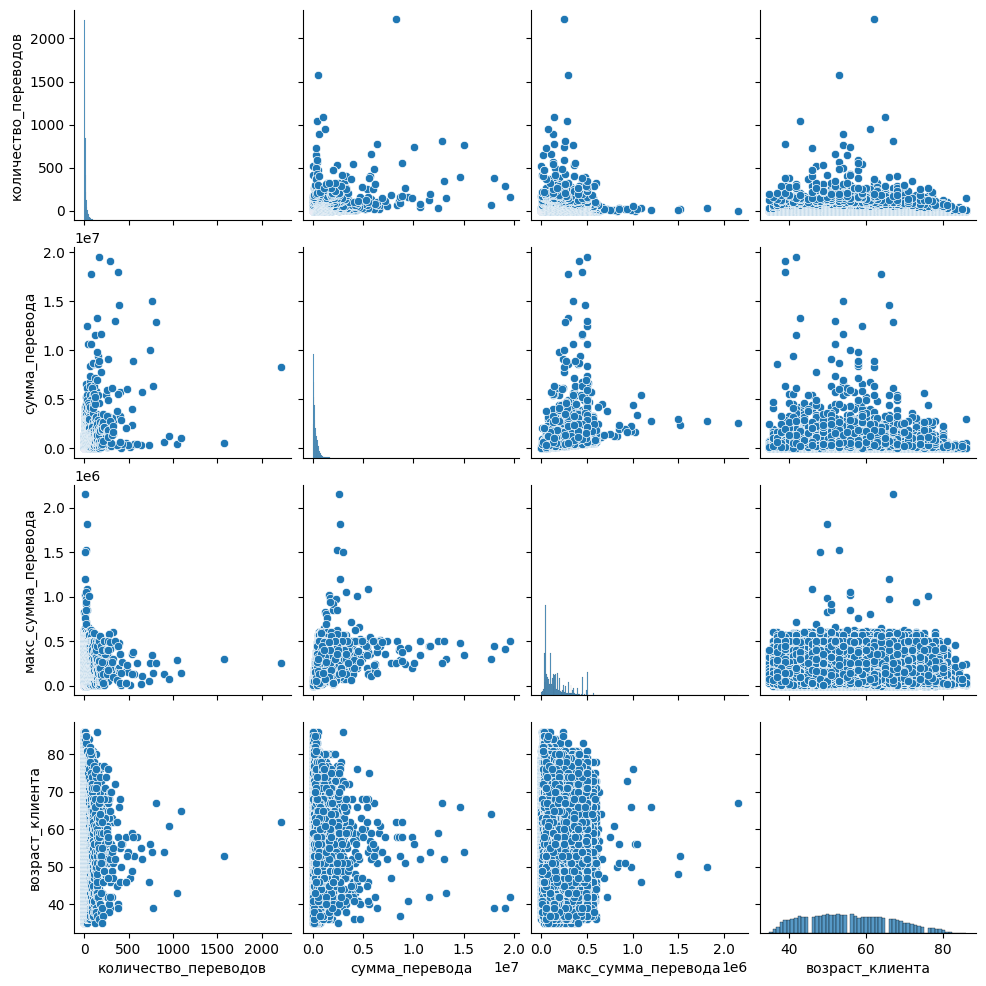

In [86]:
#  диаграмма рассеивания
sns.pairplot(df_not_anomals[lst_var_num])

In [87]:
# Промежуточные выводы
# Распределения количества и сумм переводов имеют выраженную правостороннюю асимметрию.
# Большинство клиентов характеризуется относительно небольшими значениями переводов,
# при этом присутствуют отдельные экстремально высокие значения.
# Между количеством переводов и их общей суммой прослеживается положительная зависимость.
# Явной линейной зависимости между возрастом клиентов и показателями переводов не наблюдается.

/tmp/ipykernel_738/949948387.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


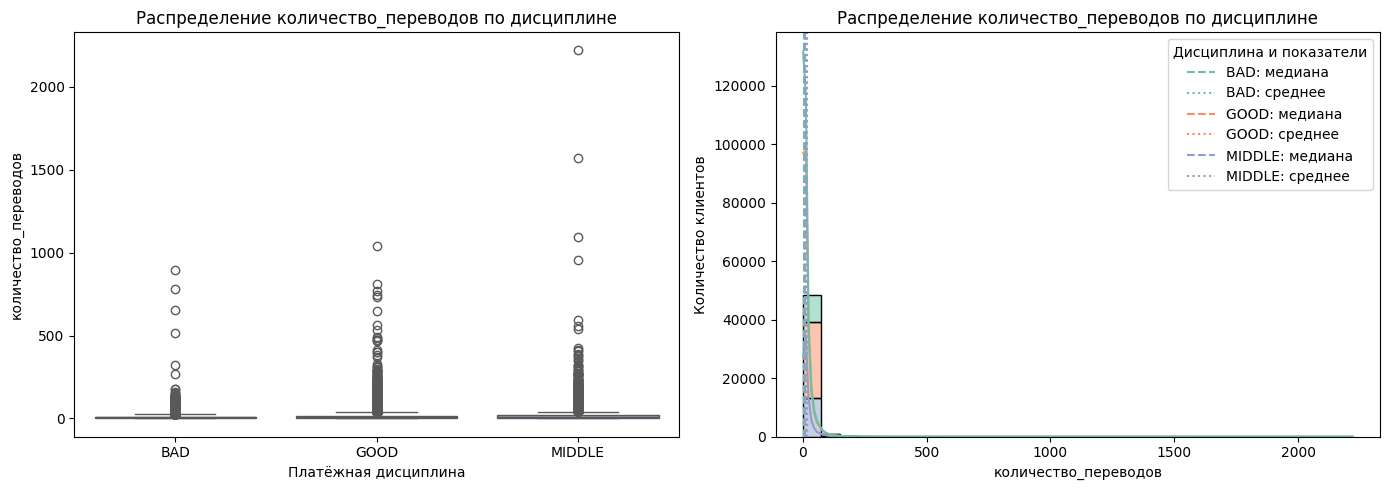

/tmp/ipykernel_738/949948387.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


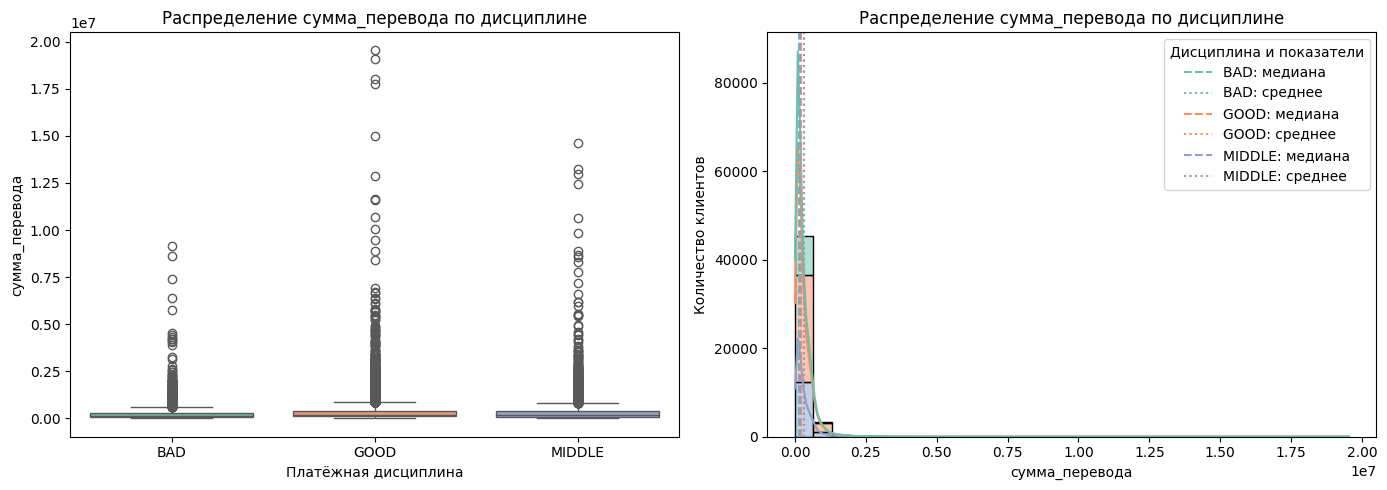

/tmp/ipykernel_738/949948387.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


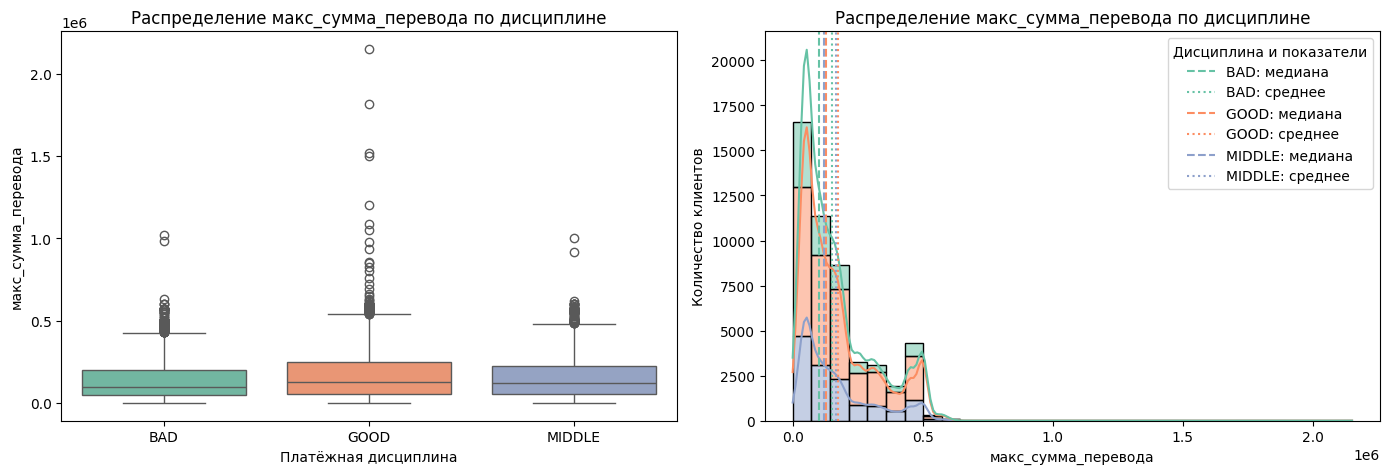

/tmp/ipykernel_738/949948387.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


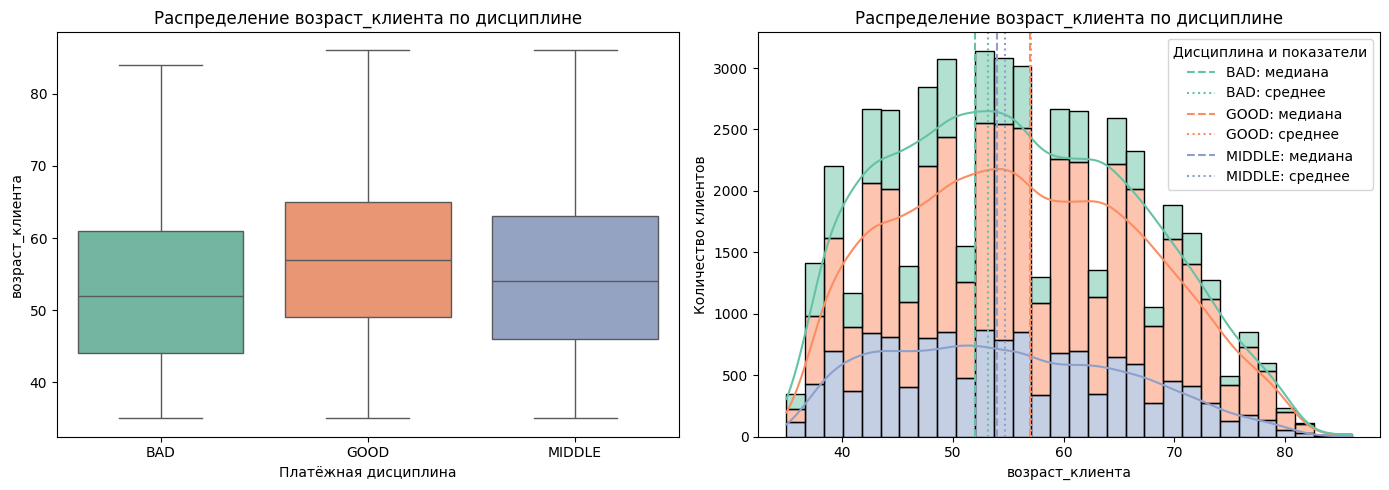

In [88]:
# Посмотрим распределения числовых признаков по дисциплине клиентов
target_col = 'дисциплина_клиента'

# Для визуализации исключаем запись без целевого признака
plot_data = df_not_anomals.dropna(subset=[target_col])

# Задаём цвета для групп
disciplines = ['BAD', 'GOOD', 'MIDDLE']
discipline_colors = {
    discipline: color
    for discipline, color in zip(
        disciplines,
        sns.color_palette('Set2', n_colors=3)
    )
}

for col in lst_var_num:
    plt.figure(figsize=(14, 5))

    # Boxplot
    plt.subplot(1, 2, 1)
    sns.boxplot(
        x=target_col,
        y=col,
        data=plot_data,
        palette=discipline_colors
    )
    plt.title(f'Распределение {col} по дисциплине')
    plt.xlabel('Платёжная дисциплина')
    plt.ylabel(col)

    # Гистограмма с KDE
    plt.subplot(1, 2, 2)
    ax = sns.histplot(
        data=plot_data,
        x=col,
        hue=target_col,
        hue_order=disciplines,
        kde=True,
        bins=30,
        multiple='stack',
        palette=discipline_colors
    )

    plt.title(f'Распределение {col} по дисциплине')
    plt.xlabel(col)
    plt.ylabel('Количество клиентов')

    # Добавляем линии медианы и среднего
    for discipline in disciplines:
        subset = plot_data.loc[
            plot_data[target_col] == discipline, col
        ].dropna()

        median_val = subset.median()
        mean_val = subset.mean()

        ax.axvline(
            median_val,
            color=discipline_colors[discipline],
            linestyle='--',
            label=f'{discipline}: медиана'
        )

        ax.axvline(
            mean_val,
            color=discipline_colors[discipline],
            linestyle=':',
            label=f'{discipline}: среднее'
        )

    plt.legend(title='Дисциплина и показатели')
    plt.tight_layout()
    plt.show()

In [89]:
# Промежуточные выводы
# По количеству переводов наибольшая активность наблюдается у клиентов
# с MIDDLE дисциплиной, наименьшая — у клиентов с BAD дисциплиной.
# По суммам переводов наиболее высокие значения характерны для группы GOOD.
# Клиенты с MIDDLE дисциплиной занимают промежуточное положение по суммам переводов.
# Во всех трех группах распределения количества и сумм переводов
# имеют выраженную правостороннюю асимметрию.
# Наблюдаются многочисленные экстремальные значения, которые не были удалены,
# поскольку они не обязательно являются ошибочными.
# Возраст клиентов с GOOD дисциплиной в среднем выше,
# чем в группах BAD и MIDDLE, однако возрастные распределения существенно перекрываются.

In [90]:
# Посмотрим графики плотности распределения без гистограмм
# и выведем на них средние и медианные значения

/tmp/ipykernel_738/4169833512.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


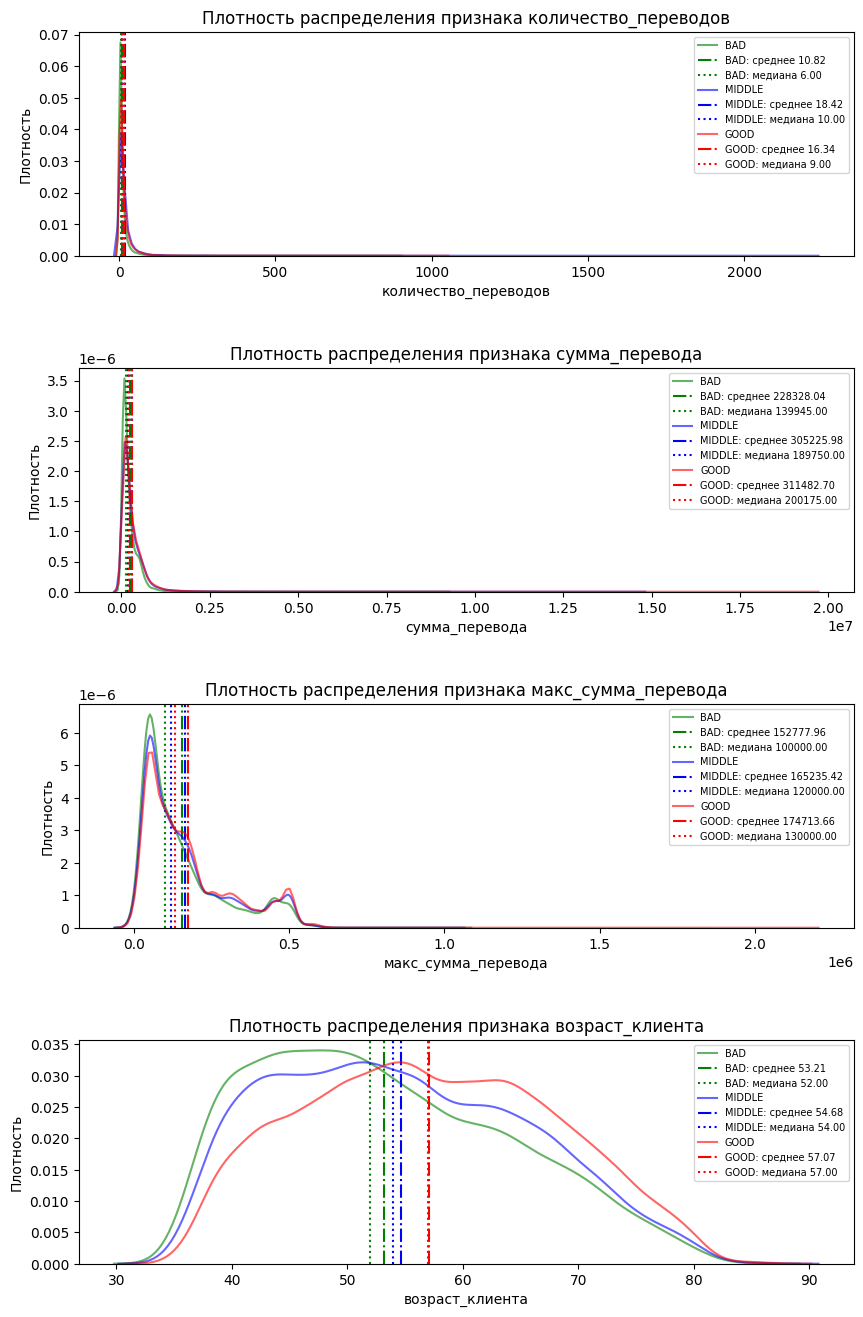

In [91]:
# Посмотрим графики плотности распределения
# и выведем на них средние и медианные значения

plt.subplots(4, 1, figsize=(10, 16),
             gridspec_kw={'wspace': 0.5, 'hspace': 0.5})

dct_color = {
    'BAD': 'green',
    'MIDDLE': 'blue',
    'GOOD': 'red'
}

disciplines = ['BAD', 'MIDDLE', 'GOOD']

for index_fig, col in enumerate(lst_var_num, start=1):
    plt.subplot(4, 1, index_fig)

    for client_status in disciplines:
        ser_temp = df_not_anomals[
            df_not_anomals['дисциплина_клиента'] == client_status
        ][col].dropna()

        color = dct_color[client_status]

        ax = sns.kdeplot(
            ser_temp,
            color=color,
            label=client_status,
            alpha=0.6
        )

        # Среднее значение
        ax.axvline(
            ser_temp.mean(),
            color=color,
            linestyle='-.',
            label=f'{client_status}: среднее {ser_temp.mean():.2f}'
        )

        # Медиана
        ax.axvline(
            ser_temp.median(),
            color=color,
            linestyle=':',
            label=f'{client_status}: медиана {ser_temp.median():.2f}'
        )

    plt.title(f'Плотность распределения признака {col}')
    plt.xlabel(col)
    plt.ylabel('Плотность')
    plt.legend(fontsize=7)

plt.tight_layout()
plt.show()

In [92]:
# Промежуточные выводы
# Графики плотности подтверждают различия между группами клиентов.
# По количеству переводов наиболее высокие показатели наблюдаются у MIDDLE,
# наименьшие — у BAD.
# По общей сумме переводов и максимальной сумме одного перевода
# лидирует группа GOOD.
# Распределения финансовых показателей во всех группах имеют правостороннюю асимметрию:
# средние значения превышают медианные.
# Клиенты GOOD в среднем старше клиентов BAD и MIDDLE.
# При этом распределения признаков между группами существенно перекрываются.

## Исследование распределения категориальных признаков в разрезе значений целевого признака `Дисциплина клиентов без просрочки по кредиту`

In [93]:
# Категориальные признаки
lst_var_disc = [
    'тип_переводов',
    'география_переводов',
    'география_телефона',
    'канал_клиента',
    'оператор_связи',
    'пол'
]

# Целевой признак для сравнения групп
target_col = 'дисциплина_клиента'

# Возраст клиента рассматриваем отдельно как числовой признак

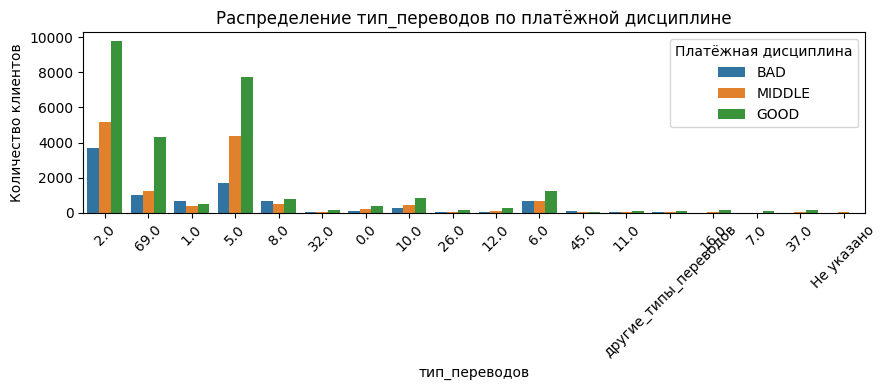

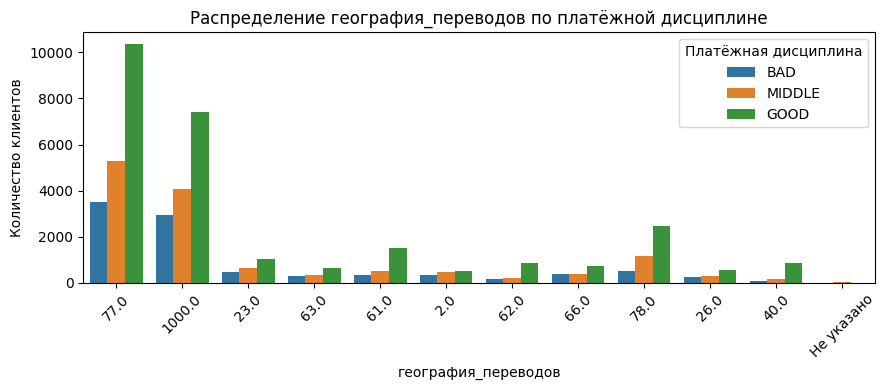

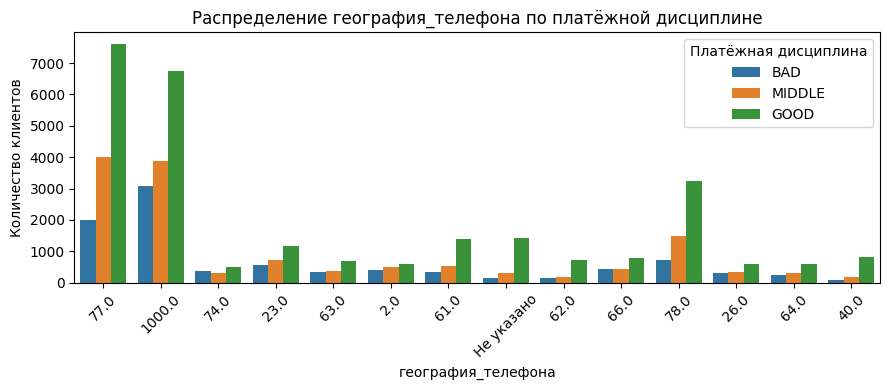

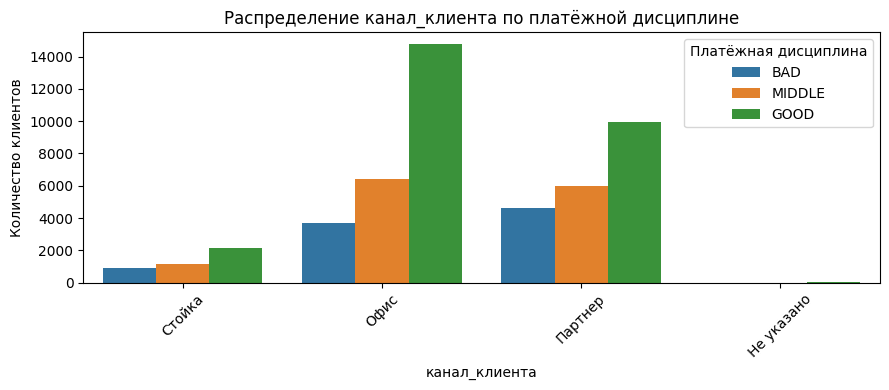

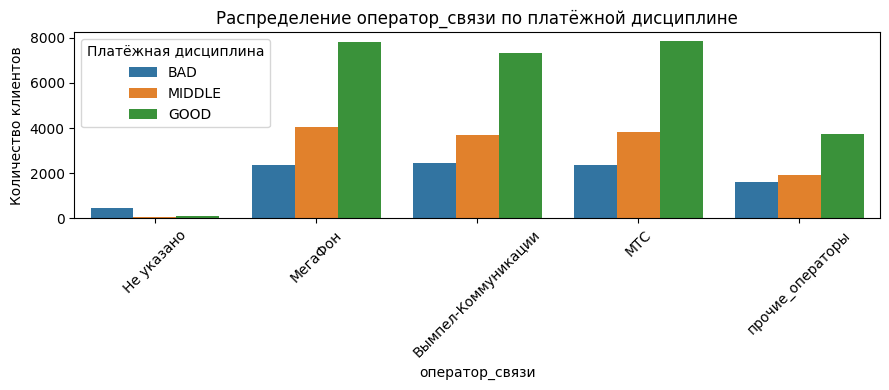

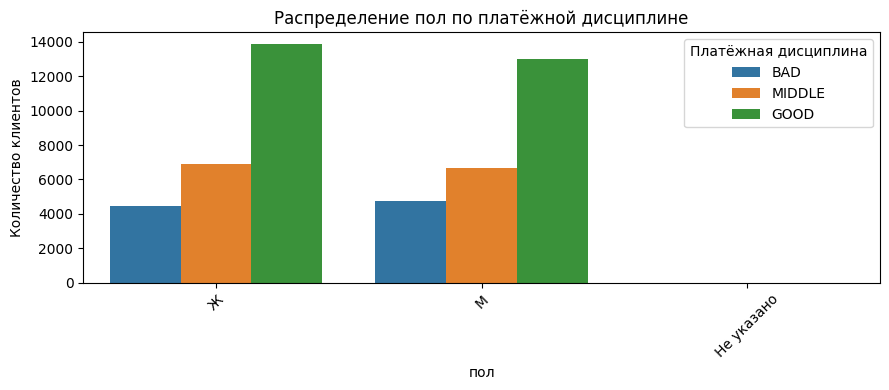

In [94]:
# Распределение категориальных признаков по платёжной дисциплине

target = 'дисциплина_клиента'

# Исключаем только запись без целевого признака
plot_data = df_not_anomals.dropna(subset=[target]).copy()

for col in lst_var_disc:

    # Пропуски показываем отдельной категорией
    plot_data[col] = plot_data[col].astype('string').fillna('Не указано')

    plt.figure(figsize=(9, 4))

    ax = sns.countplot(
        data=plot_data,
        x=col,
        hue=target,
        hue_order=['BAD', 'MIDDLE', 'GOOD']
    )

    plt.title(f'Распределение {col} по платёжной дисциплине')
    plt.xticks(rotation=45)
    plt.ylabel('Количество клиентов')
    plt.xlabel(col)
    plt.legend(title='Платёжная дисциплина')

    plt.tight_layout()
    plt.show()

In [95]:
# Промежуточные выводы
# При визуальном анализе распределений категориальных признаков
# не выявлено однозначных закономерностей, позволяющих связать
# отдельные категории с определённой платёжной дисциплиной.
# Для более точного сравнения необходимо рассмотреть
# процентное распределение категорий внутри групп BAD, GOOD и MIDDLE.

In [96]:
# Процентное распределение типов переводов внутри каждой группы дисциплины

for col in lst_var_disc:
    percent_table = pd.crosstab(
        plot_data['дисциплина_клиента'],
        plot_data[col],
        normalize='index'
    ) * 100

    print(f'\nРаспределение признака: {col}')
    display(percent_table.round(2))


Распределение признака: тип_переводов


тип_переводов,0.0,1.0,10.0,11.0,12.0,16.0,2.0,26.0,32.0,37.0,45.0,5.0,6.0,69.0,7.0,8.0,Не указано,другие_типы_переводов
дисциплина_клиента,,,,,,,,,,,,,,,,,,
BAD,1.32,7.35,3.08,0.61,0.64,0.22,40.30,0.56,0.29,0.26,1.02,18.20,7.08,10.79,0.23,7.44,0.08,0.52
GOOD,1.52,2.00,3.12,0.31,1.13,0.64,36.43,0.62,0.56,0.58,0.11,28.75,4.54,16.00,0.35,2.90,0.00,0.45
MIDDLE,1.54,3.09,3.14,0.41,0.78,0.41,38.13,0.52,0.56,0.30,0.25,32.26,4.92,9.10,0.18,3.87,0.19,0.35



Распределение признака: география_переводов


география_переводов,1000.0,2.0,23.0,26.0,40.0,61.0,62.0,63.0,66.0,77.0,78.0,Не указано
дисциплина_клиента,,,,,,,,,,,,
BAD,32.02,3.69,5.14,2.56,0.89,3.42,1.52,2.97,4.15,37.89,5.67,0.08
GOOD,27.54,1.89,3.78,2.09,3.15,5.62,3.18,2.35,2.69,38.56,9.14,0.00
MIDDLE,30.04,3.31,4.59,2.24,1.30,3.78,1.52,2.51,2.93,39.02,8.56,0.19



Распределение признака: география_телефона


география_телефона,1000.0,2.0,23.0,26.0,40.0,61.0,62.0,63.0,64.0,66.0,74.0,77.0,78.0,Не указано
дисциплина_клиента,,,,,,,,,,,,,,
BAD,33.57,4.54,6.20,3.20,0.98,3.66,1.51,3.74,2.54,4.72,4.18,21.66,7.89,1.62
GOOD,25.07,2.16,4.38,2.27,3.10,5.20,2.71,2.55,2.23,2.89,1.81,28.29,12.08,5.25
MIDDLE,28.67,3.77,5.21,2.48,1.30,3.93,1.43,2.79,2.23,3.14,2.17,29.58,11.03,2.27


... (2 outputs left out)


Распределение признака: оператор_связи


оператор_связи,Вымпел-Коммуникации,МТС,МегаФон,Не указано,прочие_операторы
дисциплина_клиента,,,,,
BAD,26.38,25.84,25.63,4.85,17.30
GOOD,27.29,29.20,29.10,0.44,13.98
MIDDLE,27.28,28.23,29.79,0.59,14.11



Распределение признака: пол


пол,Ж,М,Не указано
дисциплина_клиента,,,
BAD,48.51,51.49,0.00
GOOD,51.60,48.38,0.02
MIDDLE,50.70,49.27,0.02


In [97]:
# Промежуточные выводы

# При сравнении процентного распределения категориальных признаков
# выявлены некоторые различия между группами клиентов.
# Наиболее заметные различия наблюдаются по типу переводов,
# географии телефона и каналу привлечения.
# Клиенты BAD чаще представлены в партнёрском канале (50,37%),
# тогда как среди GOOD преобладают клиенты офисного канала (54,96%).
# Распределение по операторам связи и полу во всех трёх группах
# достаточно близкое, выраженных различий не наблюдается.
# Полученные результаты носят описательный характер и сами по себе
# не доказывают наличие статистически значимой связи с платёжной дисциплиной.

In [98]:
# отдельно рассмотрим признак 'возраст' в разрезе 'дисциплины_клиентов'

In [99]:
df_not_anomals.groupby('дисциплина_клиента')['возраст_клиента'].describe()

,count,mean,std,min,25%,50%,75%,max
дисциплина_клиента,,,,,,,,
BAD,9219.0,53.210760,10.761298,35.0,44.0,52.0,61.0,84.0
GOOD,26852.0,57.070833,10.757630,35.0,49.0,57.0,65.0,86.0
MIDDLE,13577.0,54.684835,10.770796,35.0,46.0,54.0,63.0,86.0


In [100]:
# Промежуточные выводы
# Наиболее старшая группа — клиенты с хорошей платёжной дисциплиной (GOOD),
# наиболее младшая — с плохой (BAD).
# Медианный возраст клиентов GOOD составляет 57 лет,
# BAD — 52 года, MIDDLE — 54 года.
# Разброс возраста во всех трёх группах практически одинаков.
# При этом возрастные диапазоны групп существенно перекрываются.
# Таким образом, возраст может быть одним из факторов,
# связанных с платёжной дисциплиной, но для подтверждения этой связи
# необходим дальнейший анализ.

In [101]:
#  Количество клиентов по возрастным группам (биннинг)
# Количество клиентов по возрастным группам (5-летние интервалы)
bins = range(35, 91, 5)
df_not_anomals['возраст_группы'] = pd.cut(
    df_not_anomals['возраст_клиента'],
    bins=bins,
    right=False
)

age_group_counts = df_not_anomals['возраст_группы'].value_counts().sort_index()

print("\nКоличество клиентов по возрастным группам:\n")
print(age_group_counts)




Количество клиентов по возрастным группам:

возраст_группы
[35, 40)    2851
[40, 45)    6279
[45, 50)    7060
[50, 55)    7814
[55, 60)    7168
[60, 65)    6690
[65, 70)    5644
[70, 75)    3808
[75, 80)    1943
[80, 85)     366
[85, 90)      26
Name: count, dtype: int64


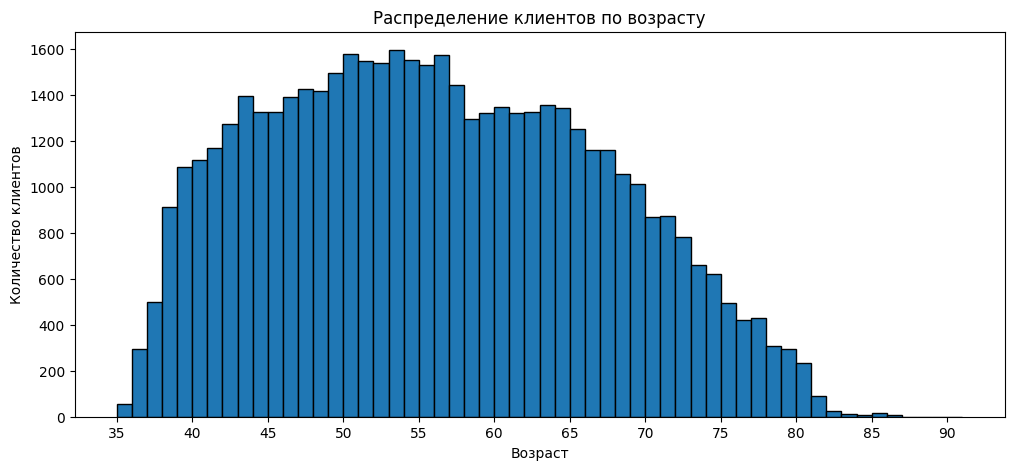

In [102]:

#  Визуализация через гистограмму
# Распределение клиентов по возрасту
plt.figure(figsize=(12, 5))
plt.hist(
    df_not_anomals['возраст_клиента'].dropna(),
    bins=range(35, 92),
    edgecolor='black'
)
plt.xlabel("Возраст")
plt.ylabel("Количество клиентов")
plt.title("Распределение клиентов по возрасту")
plt.xticks(range(35, 91, 5))
plt.show()



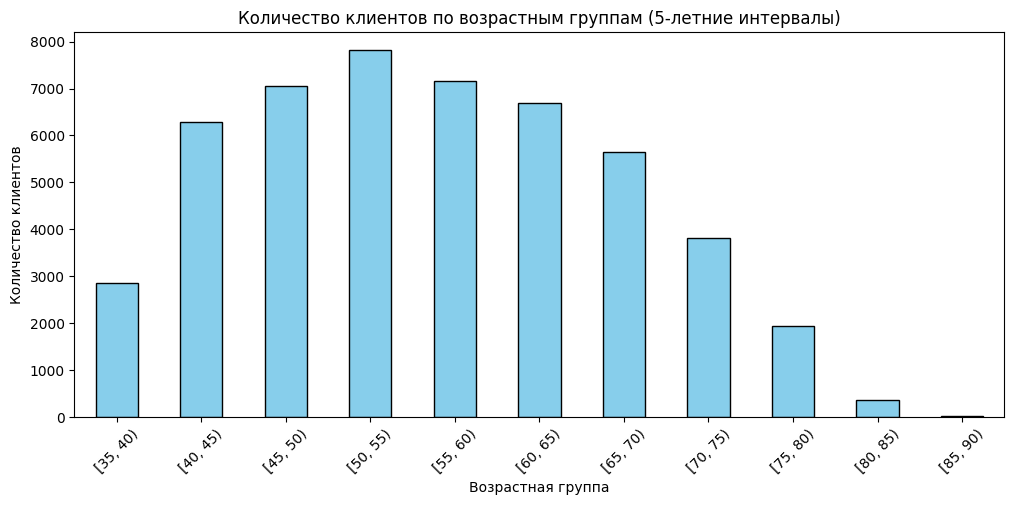

In [103]:

#  Визуализация по возрастным группам (столбчатая диаграмма)
plt.figure(figsize=(12,5))
age_group_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.xlabel("Возрастная группа")
plt.ylabel("Количество клиентов")
plt.title("Количество клиентов по возрастным группам (5-летние интервалы)")
plt.xticks(rotation=45)
plt.show()

In [104]:
# Промежуточные выводы
# Основная часть клиентов находится в возрастном диапазоне 40–70 лет.
# Наиболее многочисленная возрастная группа — 50–55 лет.
# После 65 лет наблюдается постепенное снижение количества клиентов.
# Клиенты старше 80 лет составляют небольшую часть выборки.

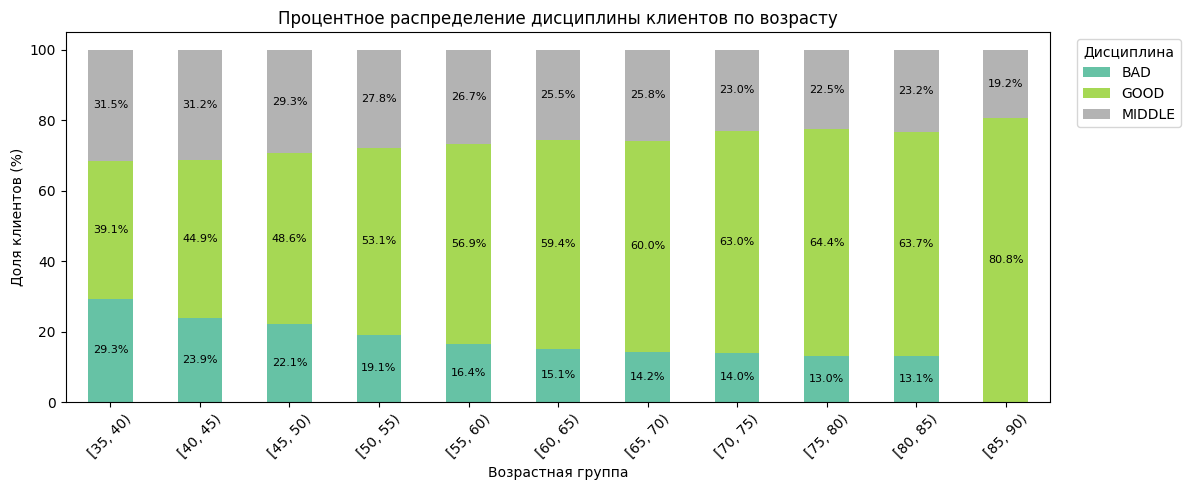

In [105]:
# Процентное распределение платёжной дисциплины по возрастным группам
plot_data_age = df_not_anomals.dropna(subset=['дисциплина_клиента', 'возраст_группы'])

ctab_pct = pd.crosstab(
    plot_data_age['возраст_группы'],
    plot_data_age['дисциплина_клиента'],
    normalize='index'
) * 100

ax = ctab_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 5),
    colormap='Set2'
)

plt.title("Процентное распределение дисциплины клиентов по возрасту")
plt.xlabel("Возрастная группа")
plt.ylabel("Доля клиентов (%)")
plt.xticks(rotation=45)

for i, row in enumerate(ctab_pct.values):
    cum_height = 0
    for val in row:
        if val > 0:
            ax.text(
                i,
                cum_height + val / 2,
                f"{val:.1f}%",
                ha='center',
                va='center',
                fontsize=8,
                color='black'
            )
        cum_height += val

plt.legend(title="Дисциплина", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

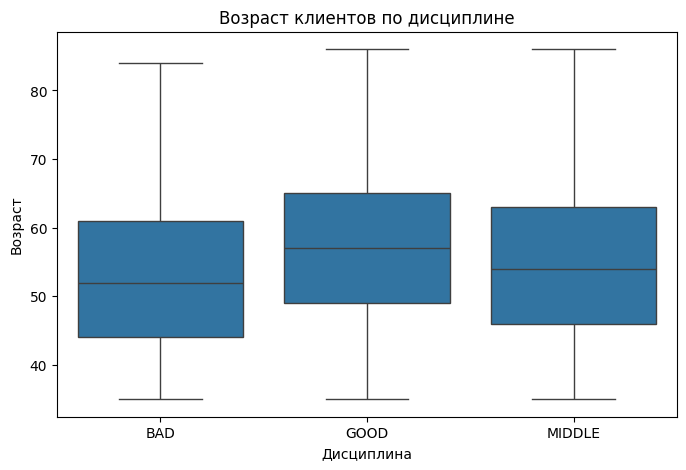

In [106]:

#  Boxplot для распределения возраста по дисциплине
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_not_anomals, x='дисциплина_клиента', y='возраст_клиента')
plt.title("Возраст клиентов по дисциплине")
plt.ylabel("Возраст")
plt.xlabel("Дисциплина")
plt.show()

In [107]:
# Промежуточные выводы
# При увеличении возраста клиентов наблюдается снижение доли BAD
# и увеличение доли GOOD.
# Наиболее высокая доля GOOD наблюдается в возрастных группах 70–85 лет.
# Доля клиентов с дисциплиной MIDDLE также постепенно снижается.
# Медианный возраст клиентов GOOD выше, чем в группах BAD и MIDDLE.
# Полученные результаты указывают на связь возраста с платёжной дисциплиной,
# однако не доказывают причинно-следственную зависимость.
# При интерпретации результатов необходимо учитывать численность
# отдельных возрастных групп.

In [108]:
# Количество клиентов в возрастных группах (5-летние интервалы)
bins = range(35, 91, 5)

df_not_anomals['возраст_группы'] = pd.cut(
    df_not_anomals['возраст_клиента'],
    bins=bins,
    right=False
)

age_group_counts = df_not_anomals['возраст_группы'].value_counts().sort_index()

print("Количество клиентов по возрастным группам:")
display(age_group_counts)

Количество клиентов по возрастным группам:


,count
возраст_группы,
"[35, 40)",2851
"[40, 45)",6279
"[45, 50)",7060
"[50, 55)",7814
"[55, 60)",7168
"[60, 65)",6690
"[65, 70)",5644
"[70, 75)",3808
"[75, 80)",1943


In [109]:
# Промежуточные выводы
# Наиболее многочисленная возрастная группа — 50–55 лет (7 819 клиентов).
# Основная часть клиентов сосредоточена в возрасте от 40 до 70 лет.
# После 70 лет количество клиентов постепенно снижается.
# Возрастная группа 85–90 лет малочисленна (26 клиентов),
# поэтому результаты по ней требуют осторожной интерпретации.

In [110]:
# Описательная статистика возраста по платёжной дисциплине
age_stats = df_not_anomals.groupby('дисциплина_клиента')['возраст_клиента'].describe()

display(age_stats.round(1))

,count,mean,std,min,25%,50%,75%,max
дисциплина_клиента,,,,,,,,
BAD,9219.0,53.2,10.8,35.0,44.0,52.0,61.0,84.0
GOOD,26852.0,57.1,10.8,35.0,49.0,57.0,65.0,86.0
MIDDLE,13577.0,54.7,10.8,35.0,46.0,54.0,63.0,86.0


In [111]:
# Промежуточные выводы по описательной статистике возраста
# Средний и медианный возраст клиентов с хорошей платёжной дисциплиной (GOOD)
# выше, чем у клиентов с BAD и MIDDLE.
# Минимальный возраст во всех группах одинаковый, максимальный отличается незначительно.
# Разброс возраста во всех трёх группах практически одинаков.

# Промежуточные выводы по возрастным группам
# Диаграмма показывает процентное распределение клиентов с разной
# платёжной дисциплиной внутри каждой возрастной группы.
# Наблюдается тенденция к снижению доли BAD и увеличению доли GOOD
# по мере увеличения возраста клиентов.
# Доля клиентов с дисциплиной MIDDLE также в целом снижается,
# хотя изменения менее выражены.
# В старших возрастных группах доля GOOD выше, однако необходимо учитывать,
# что численность этих групп значительно меньше.
# Особенно малочисленна группа 85–90 лет (26 клиентов),
# поэтому результаты по ней требуют осторожной интерпретации.

## Сформулируем и проверим гипотезы:

*   H₀ (нулевая): средний возраст клиентов с GOOD не выше среднего возраста
*   H₁ (альтернативная): средний возраст клиентов с GOOD статистически выше среднего возраста клиентов с BAD.

клиентов с BAD.

В математической форме:
$$
H_0: \mu_{GOOD} \leq \mu_{BAD}
$$

$$
H_1: \mu_{GOOD} > \mu_{BAD}
$$


In [129]:
# сделаем выборки по возрасту и дисциплине
age_good = df_not_anomals[df_not_anomals['дисциплина_клиента']=='GOOD']['возраст_клиента'].dropna()

age_bad  = df_not_anomals[df_not_anomals['дисциплина_клиента']=='BAD']['возраст_клиента'].dropna()

In [130]:
# посчитаем коэффициенты Шапиро и проверим выборки на нормальность распределения
print(stats.shapiro(age_good))
print(stats.shapiro(age_bad))

ShapiroResult(statistic=np.float64(0.9819412550579341), pvalue=np.float64(1.5285405584616306e-48))
ShapiroResult(statistic=np.float64(0.9639848989827791), pvalue=np.float64(7.333844890018927e-43))


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 26852.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 9219.
  res = hypotest_fun_out(*samples, **kwds)


In [115]:
# Выводы
# Для обеих выборок p-value значительно меньше 0.05.
# Следовательно, гипотеза о нормальности распределения возраста отвергается.
# Для дальнейшей проверки гипотезы о различии среднего возраста
# используем t-критерий Уэлча, который не требует равенства дисперсий
# и устойчив к отклонениям от нормальности при больших объёмах выборок.

In [132]:
# Проверка гипотезы о различии среднего возраста
# Односторонний t-критерий Уэлча: GOOD > BAD

t_stat, p_value = stats.ttest_ind(
    age_good,
    age_bad,
    equal_var=False,
    alternative='greater'
)

print(f"t-статистика: {t_stat:.4f}")
print(f"p-value: {p_value:.6g}")

t-статистика: 29.7180
p-value: 2.98138e-189


In [117]:
# Выводы по результатам t-критерия Уэлча
# p-value значительно меньше уровня значимости 0.05.
# Нулевая гипотеза H0 отвергается.
# Получены статистические основания утверждать, что средний возраст
# клиентов с хорошей платёжной дисциплиной (GOOD) выше,
# чем средний возраст клиентов с плохой дисциплиной (BAD).
# Различие статистически значимо.


In [133]:
# выбираем  дисциплину и возраст и посмотрим их средние и медианы в таблице
# выбираем только BAD и GOOD
df_age_disc = df_not_anomals[df_not_anomals['дисциплина_клиента'].isin(['BAD','GOOD'])][['дисциплина_клиента', 'возраст_клиента']]

# проходим по каждой дисциплине
for disc in ['BAD', 'GOOD']:
    subset = df_age_disc[df_age_disc['дисциплина_клиента']==disc]
    mean_val = round(subset['возраст_клиента'].mean(), 2)
    median_val = subset['возраст_клиента'].median()
    print(f"Дисциплина: {disc}")
    print(f"  Выборочное среднее возраста: {mean_val}")
    print(f"  Медиана возраста: {median_val}\n")

Дисциплина: BAD
  Выборочное среднее возраста: 53.21
  Медиана возраста: 52.0

Дисциплина: GOOD
  Выборочное среднее возраста: 57.07
  Медиана возраста: 57.0



In [ ]:
# Выводы
# Средний возраст клиентов GOOD составляет 57,07 года,
# BAD — 53,21 года.
# Разница средних возрастов составляет 3,86 года.
# Медианный возраст GOOD также выше: 57 лет против 52 лет у BAD.
# Результаты согласуются с выводами статистического теста Уэлча.

In [119]:
#  на графиках

/tmp/ipykernel_738/3190811452.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


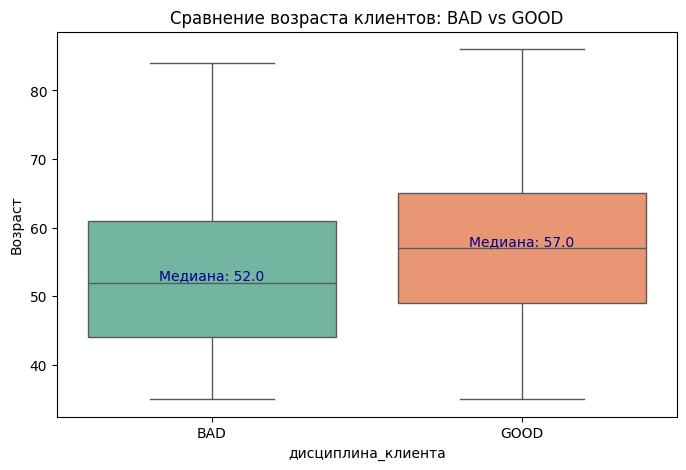

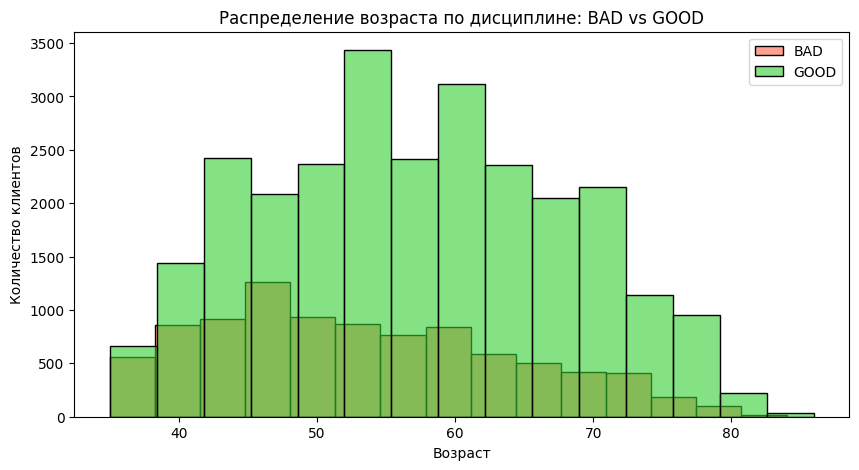

In [120]:
# фильтруем только BAD и GOOD
df_compare = df_not_anomals[df_not_anomals['дисциплина_клиента'].isin(['BAD','GOOD'])]

# Boxplot
plt.figure(figsize=(8,5))
ax = sns.boxplot(
    data=df_compare,
    x='дисциплина_клиента',
    y='возраст_клиента',
    palette='Set2',
    showfliers=True,
    flierprops=dict(marker='o', markerfacecolor='red', markersize=6, alpha=0.7)
)

# подписи медиан
for i, group in enumerate(['BAD','GOOD']):
    median_val = df_compare[df_compare['дисциплина_клиента']==group]['возраст_клиента'].median()
    ax.text(
        x=i,
        y=median_val,
        s=f"Медиана: {median_val}",
        ha='center',
        va='bottom',
        fontsize=10,
        color='darkblue'
    )

plt.title("Сравнение возраста клиентов: BAD vs GOOD")
plt.ylabel("Возраст")
plt.show()

# Гистограммы
plt.figure(figsize=(10,5))
sns.histplot(df_compare[df_compare['дисциплина_клиента']=='BAD']['возраст_клиента'],
             color='tomato', label='BAD', kde=False, bins=15, alpha=0.6)
sns.histplot(df_compare[df_compare['дисциплина_клиента']=='GOOD']['возраст_клиента'],
             color='limegreen', label='GOOD', kde=False, bins=15, alpha=0.6)

plt.xlabel("Возраст")
plt.ylabel("Количество клиентов")
plt.title("Распределение возраста по дисциплине: BAD vs GOOD")
plt.legend()
plt.show()


In [ ]:
# Выводы по визуальному анализу
# Медианный возраст клиентов GOOD (57 лет) выше, чем BAD (52 года).
# Распределение возраста GOOD смещено в сторону старших возрастов.
# Клиенты BAD чаще представлены в более молодых возрастных группах.
# При этом возрастные распределения обеих групп существенно перекрываются.
# Визуальные наблюдения согласуются с результатами
# описательной статистики и t-критерия Уэлча.

In [121]:
# Выводы по гипотезам:
# Отвергаем нулевую гипотезу H0 в пользу альтернативной H1.
# Получены статистические основания утверждать, что средний возраст
# клиентов с дисциплиной GOOD статистически значимо выше,
# чем у клиентов с дисциплиной BAD.

In [122]:
# посмотрим матрицу корреляции

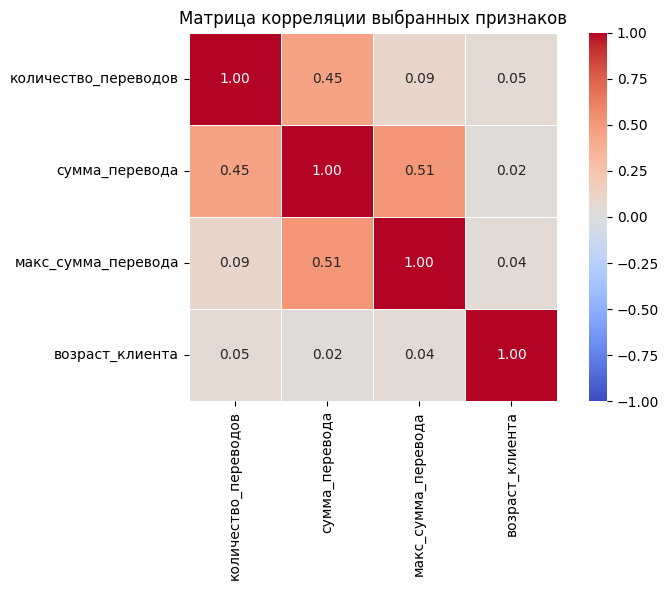

In [135]:
# Выбираем только числовые столбцы
numeric_cols = [
    'количество_переводов',
    'сумма_перевода',
    'макс_сумма_перевода',
    'возраст_клиента'
]

# Формируем таблицу числовых признаков
df_numeric = df_not_anomals[numeric_cols]

# Рассчитываем корреляцию Пирсона
corr_matrix = df_numeric.corr(method='pearson')

# Визуализация матрицы корреляции
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    square=True,
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Матрица корреляции выбранных признаков")
plt.tight_layout()
plt.show()

In [ ]:
# Выводы по матрице корреляции
# Наиболее выраженная положительная корреляция наблюдается
# между суммой переводов и максимальной суммой перевода (0.51).
# Также выявлена умеренная положительная связь между количеством
# переводов и общей суммой переводов (0.45).
# Между количеством переводов и максимальной суммой перевода
# связь очень слабая (0.09).
# Возраст клиента практически не имеет линейной взаимосвязи
# с количеством, общей и максимальной суммой переводов
# (коэффициенты корреляции от 0.02 до 0.05).

In [125]:
# выгрузим обработанные данные в файл для построения дашборда
df_not_anomals.to_csv('df_not_anomals.csv', index=False, encoding='utf-8-sig')

## В разрезе значений целевого признака составить портреты клиентов платежной системы.

## Портреты клиентов в разрезе платёжной дисциплины

### Портрет клиента с дисциплиной BAD (повышенный риск)

**1. Возраст**

Относительно более молодая группа по сравнению с GOOD. Средний возраст составляет 53,2 года, медианный — 52 года.

**2. Финансовое поведение**

- Количество переводов: в среднем 10,8, медиана — 6.
- Средняя сумма переводов — около 228 тыс. рублей, медианная — около 140 тыс. рублей.
- Средняя максимальная сумма перевода — около 153 тыс. рублей, медианная — 100 тыс. рублей.

По рассмотренным числовым показателям группа BAD демонстрирует наименьшую финансовую активность.

**3. Канал привлечения**

Преобладает партнёрский канал (50,37%), далее следует офис банка (39,81%).

**4. Ключевая характеристика**

Клиент с плохой платёжной дисциплиной, который в среднем совершает меньше переводов и оперирует меньшими суммами по сравнению с GOOD и MIDDLE. Группа представляет интерес для дальнейшего изучения факторов, связанных с повышенным кредитным риском.

### Портрет клиента с дисциплиной MIDDLE (средний риск)

**1. Возраст**

Средний возраст составляет 54,7 года, медианный — 54 года. По возрасту группа занимает промежуточное положение между BAD и GOOD.

**2. Финансовое поведение**

- Количество переводов: в среднем 18,4, медиана — 10.
- Средняя сумма переводов — около 305 тыс. рублей, медианная — около 190 тыс. рублей.
- Средняя максимальная сумма перевода — около 165 тыс. рублей, медианная — 120 тыс. рублей.

Группа MIDDLE характеризуется наибольшим средним количеством переводов среди трёх категорий.

**3. Канал привлечения**

Распределение между партнёрским каналом (43,90%) и офисом банка (47,49%) достаточно близкое.

**4. Ключевая характеристика**

Клиент со средним уровнем платёжной дисциплины, демонстрирующий достаточно высокую финансовую активность. Группа может представлять интерес для дополнительного анализа факторов, связанных с переходом к более высокой категории платёжной дисциплины.

### Портрет клиента с дисциплиной GOOD (низкий риск)

**1. Возраст**

Наиболее старшая группа клиентов. Средний возраст составляет 57,1 года, медианный — 57 лет.

**2. Финансовое поведение**

- Количество переводов: в среднем 16,3, медиана — 9.
- Средняя сумма переводов — около 311 тыс. рублей, медианная — около 200 тыс. рублей.
- Средняя максимальная сумма перевода — около 175 тыс. рублей, медианная — 130 тыс. рублей.

Клиенты GOOD характеризуются наибольшими средними и медианными суммами переводов среди трёх категорий.

**3. Канал привлечения**

Преобладает офисный канал (54,96%), доля партнёрского канала составляет 37,08%.

**4. Ключевая характеристика**

Клиент с хорошей платёжной дисциплиной, который в среднем совершает переводы на более крупные суммы и имеет более высокий возраст по сравнению с другими группами.

## Выводы по этапу исследовательского анализа

## Выводы по этапу исследовательского анализа

На этапе исследовательского анализа данных были выполнены следующие работы:

**1. Исследовано распределение числовых признаков в разрезе значений целевого признака — платёжной дисциплины клиентов.**

Выявлено, что:
- Клиенты GOOD имеют наибольшие средние и медианные суммы переводов, а также максимальные суммы отдельных переводов.
- Наибольшее среднее количество переводов наблюдается в группе MIDDLE.
- Клиенты BAD характеризуются наименьшими значениями основных показателей финансовой активности.
- Клиенты GOOD в среднем старше клиентов BAD и MIDDLE.

**2. Исследовано распределение категориальных признаков.**

- Наиболее заметные различия между группами наблюдаются по типу переводов, географии телефона и каналу привлечения.
- Среди клиентов BAD преобладает партнёрский канал (50,37%).
- Среди клиентов GOOD преобладает офисный канал (54,96%).
- Распределения по полу и оператору связи между группами достаточно близкие.

**3. Проведён отдельный анализ возраста клиентов.**

- Основная часть клиентов находится в возрастном диапазоне 40–70 лет.
- Наиболее многочисленная возрастная группа — 50–55 лет.
- При увеличении возраста наблюдается снижение доли BAD и увеличение доли GOOD.
- Старшие возрастные группы малочисленны, поэтому результаты по ним требуют осторожной интерпретации.

**4. Сформулирована и проверена статистическая гипотеза о различии среднего возраста клиентов GOOD и BAD.**

- Нулевая гипотеза H₀: средний возраст GOOD не выше среднего возраста BAD.
- Альтернативная гипотеза H₁: средний возраст GOOD выше среднего возраста BAD.
- Для проверки использован односторонний t-критерий Уэлча.
- Получено p-value = 2,98 × 10⁻¹⁸⁹, что значительно меньше уровня значимости 0,05.
- Нулевая гипотеза отвергнута. Получены статистические основания утверждать, что средний возраст клиентов GOOD выше среднего возраста BAD.
- Разница средних возрастов составляет около 3,86 года.

**5. Построена и проанализирована матрица корреляции числовых признаков.**

- Наиболее выраженная положительная корреляция выявлена между суммой переводов и максимальной суммой перевода (0,51).
- Между количеством переводов и общей суммой переводов наблюдается умеренная положительная связь (0,45).
- Возраст практически не имеет линейной корреляции с показателями финансовой активности клиентов.

**6. Сформированы портреты клиентов по категориям платёжной дисциплины BAD, MIDDLE и GOOD.**

# Общие выводы по проекту



## Общие выводы по проекту

В рамках проекта «Выделение портретов заёмщиков банка» проведён исследовательский анализ данных с целью выявления особенностей клиентов в зависимости от их платёжной дисциплины.

В ходе работы:
- Проведена предварительная обработка данных и оценка их качества.
- Исследованы числовые и категориальные признаки в разрезе целевого признака «Дисциплина клиента».
- Изучены особенности возрастной структуры заёмщиков.
- Проверена статистическая гипотеза о различии среднего возраста клиентов с хорошей и плохой платёжной дисциплиной.
- Построена и проанализирована матрица корреляции числовых признаков.
- Сформированы портреты заёмщиков для каждой категории целевого признака: BAD, MIDDLE и GOOD.
- Подготовлен обработанный набор данных для последующего построения дашборда.

**Основные результаты анализа:**

Выявлены различия между группами заёмщиков по возрасту, финансовой активности и каналам привлечения.

Клиенты с хорошей платёжной дисциплиной (GOOD) в среднем старше клиентов BAD, совершают переводы на более крупные суммы и чаще привлекаются через офисный канал.

Клиенты с плохой платёжной дисциплиной (BAD) характеризуются меньшими показателями финансовой активности и более высокой долей партнёрского канала.

Группа MIDDLE отличается наибольшим средним количеством переводов среди трёх категорий.

По результатам исследования сформированы три портрета заёмщиков, отражающие характерные особенности каждой группы платёжной дисциплины.

Полученные результаты могут использоваться для сегментации клиентской базы, разработки маркетинговых предложений и дальнейшего исследования факторов, связанных с кредитными рисками.

#